# EDA: Loghub (HDFS_v1 e BGL)

Nicho: **logs de sistema** (classificado como Disco/Memória na síntese). Duas bases com rótulos de natureza diferente:

| Base | Rótulo | Unidade de análise |
|---|---|---|
| HDFS_v1 | Normal/Anomalia por **trace** (um `BlockId`) | trace |
| BGL | Alerta (categoria) ou não-alerta (`-`) por **mensagem** | linha de log |

Fonte: Loghub, Zenodo DOI 10.5281/zenodo.8196385 (CC-BY-4.0). Os brutos ficam em `data/raw/loghub/` (não alterados); os arquivos extraídos em `data/interim/loghub/`.

Perguntas: (1) o rótulo é confiável e balanceado? (2) há duplicatas e vazamento? (3) um baseline simples já separa as classes? (4) cabe na máquina (16 GB de RAM)?

In [1]:
from pathlib import Path
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, average_precision_score

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
ROOT = Path.cwd().parent
HDFS = ROOT / "data/interim/loghub/hdfs"
BGL = ROOT / "data/interim/loghub/bgl"
SEED = 42

def metricas(y, p, score):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="binary", zero_division=0)
    return dict(precisao=pr, recall=rc, f1=f1, pr_auc=average_precision_score(y, score))

## 1. HDFS_v1

### 1.1 Rótulos por trace

In [2]:
lab = pd.read_csv(HDFS / "preprocessed/anomaly_label.csv")
vc = lab["Label"].value_counts()
print(vc.to_string())
print(f"traces: {len(lab):,} | BlockId únicos: {lab.BlockId.nunique():,} | taxa de anomalia: {vc['Anomaly']/len(lab):.2%}")
print(f"razão normal:anomalia = {vc['Normal']/vc['Anomaly']:.1f}:1")

Label
Normal     558223
Anomaly     16838
traces: 575,061 | BlockId únicos: 575,061 | taxa de anomalia: 2.93%
razão normal:anomalia = 33.2:1


### 1.2 Matriz de ocorrência de eventos (E1 a E29)

In [3]:
mat = pd.read_csv(HDFS / "preprocessed/Event_occurrence_matrix.csv")
ev = [c for c in mat.columns if c.startswith("E") and c[1:].isdigit()]
print(mat.shape, f"| memória: {mat.memory_usage(deep=True).sum()/1e6:.0f} MB | colunas de evento: {len(ev)}")
print(mat[["BlockId","Label","Type"]].head(3).to_string())
print("\nLabel:", mat.Label.value_counts().to_dict())
print("Type (não nulos):", mat.Type.notna().sum(), "| valores distintos:", mat.Type.nunique())
print("\nNulos nas colunas de evento:", int(mat[ev].isna().sum().sum()))

(575061, 32) | memória: 165 MB | colunas de evento: 29
                    BlockId    Label  Type
0  blk_-1608999687919862906  Success   NaN
1   blk_7503483334202473044  Success   NaN
2  blk_-3544583377289625738     Fail  21.0

Label: {'Success': 558223, 'Fail': 16838}
Type (não nulos): 16838 | valores distintos: 26

Nulos nas colunas de evento: 0


Conferência cruzada: o rótulo da matriz (`Success`/`Fail`) é o mesmo do `anomaly_label.csv` (`Normal`/`Anomaly`)?

In [4]:
j = mat[["BlockId","Label"]].merge(lab, on="BlockId", how="outer", suffixes=("_mat","_lab"), indicator=True)
print(j["_merge"].value_counts().to_dict())
print(pd.crosstab(j.Label_mat, j.Label_lab, dropna=False))

{'both': 575061, 'left_only': 0, 'right_only': 0}
Label_lab  Anomaly  Normal
Label_mat                 
Fail         16838       0
Success          0  558223


### 1.3 Tamanho dos traces e perfil dos eventos

      count  mean   std   min   25%   50%   75%    max
y                                                     
0  558223.0  19.5   4.8  13.0  19.0  19.0  20.0  298.0
1   16838.0  17.1  12.4   2.0   4.0  20.0  26.0  284.0


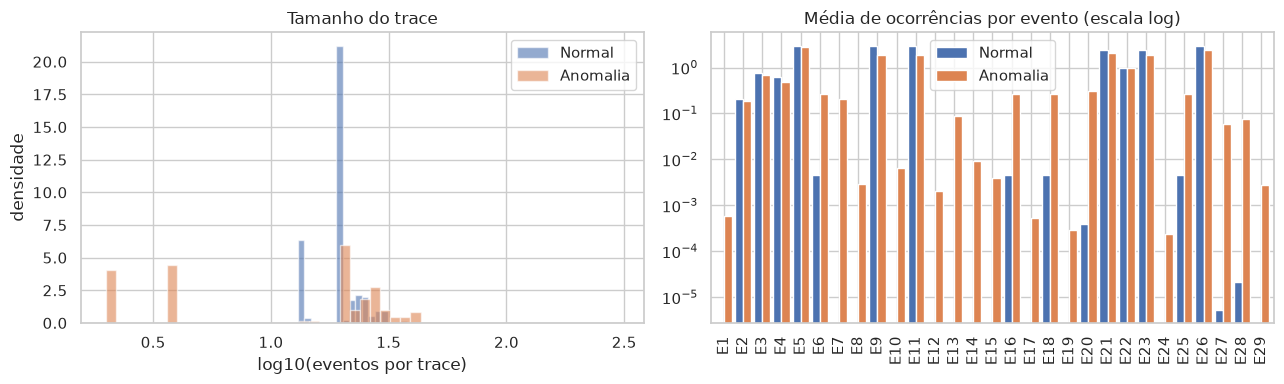

In [5]:
mat["y"] = (mat.Label == "Fail").astype(int)
mat["n_eventos"] = mat[ev].sum(axis=1)
print(mat.groupby("y").n_eventos.describe().round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for y, nome in [(0, "Normal"), (1, "Anomalia")]:
    ax[0].hist(np.log10(mat.loc[mat.y == y, "n_eventos"].clip(lower=1)), bins=50, alpha=.6, label=nome, density=True)
ax[0].set(xlabel="log10(eventos por trace)", ylabel="densidade", title="Tamanho do trace")
ax[0].legend()
media = mat.groupby("y")[ev].mean().T
media.columns = ["Normal", "Anomalia"]
media.plot.bar(ax=ax[1], width=.85, logy=True)
ax[1].set(title="Média de ocorrências por evento (escala log)", xlabel="")
plt.tight_layout(); plt.show()

Eventos que só aparecem em um dos dois grupos (candidatos a vazamento ou a sinal forte):

In [6]:
pres = mat.groupby("y")[ev].apply(lambda d: (d > 0).mean()).T
pres.columns = ["frac_normal", "frac_anomalia"]
pres["razao"] = (pres.frac_anomalia + 1e-9) / (pres.frac_normal + 1e-9)
tpl = pd.read_csv(HDFS / "preprocessed/HDFS.log_templates.csv").set_index("EventId").EventTemplate
pres["template"] = tpl.reindex(pres.index).str.slice(0, 70)
print(pres.sort_values("razao", ascending=False).round(3).head(8).to_string())
print("\nExclusivos de um grupo:", pres[(pres.frac_normal == 0) | (pres.frac_anomalia == 0)].index.tolist())

     frac_normal  frac_anomalia         razao                                                                template
E7           0.0          0.196  1.961634e+08                                   [*]writeBlock[*]received exception[*]
E13          0.0          0.029  2.898207e+07                                  [*]Receiving empty packet for block[*]
E10          0.0          0.004  3.979096e+06                                       [*]PacketResponder[*]Exception[*]
E14          0.0          0.004  3.741538e+06                               [*]Exception in receiveBlock for block[*]
E8           0.0          0.003  2.731917e+06                         [*]PacketResponder[*]for block[*]Interrupted[*]
E29          0.0          0.003  2.731917e+06                         [*]PendingReplicationMonitor timed out block[*]
E15          0.0          0.002  2.256801e+06  [*]Changing block file offset of block[*]from[*]to[*]meta file offset 
E12          0.0          0.002  1.544127e+06           

### 1.4 Duplicatas e conflito de rótulo

In [7]:
X = mat[ev].to_numpy()
mat["vec"] = pd.util.hash_pandas_object(mat[ev], index=False).to_numpy()
g = mat.groupby("vec").agg(n=("y", "size"), pos=("y", "sum"))
assert len(g) == len(mat[ev].drop_duplicates()), "hash colidiu"
print(f"vetores distintos: {len(g):,} de {len(mat):,} traces ({len(g)/len(mat):.2%})")
print(f"vetores que aparecem uma única vez: {(g.n == 1).sum()} | o maior vetor sozinho cobre {g.n.max():,} traces ({g.n.max()/len(mat):.1%})")
conf = g[(g.pos > 0) & (g.pos < g.n)]
print(f"vetores com rótulos conflitantes: {len(conf):,} cobrindo {int(conf.n.sum()):,} traces ({conf.n.sum()/len(mat):.2%})")
print("Traces cujo vetor aparece mais de uma vez:", f"{(mat.vec.map(g.n) > 1).mean():.1%}")

vetores distintos: 589 de 575,061 traces (0.10%)
vetores que aparecem uma única vez: 204 | o maior vetor sozinho cobre 300,395 traces (52.2%)
vetores com rótulos conflitantes: 9 cobrindo 550 traces (0.10%)
Traces cujo vetor aparece mais de uma vez: 100.0%


### 1.5 Perfil do log bruto (DuckDB, sem carregar 1,5 GB na RAM)

In [8]:
con = duckdb.connect(str(ROOT / "data/interim/loghub/loghub.duckdb"))
con.execute("SET memory_limit='3GB'")
con.execute(f"""
CREATE OR REPLACE TABLE hdfs_raw AS
SELECT regexp_extract(l, '^\\d+ \\d+ \\d+ (\\w+) ', 1) AS nivel,
       regexp_extract(l, '^\\d+ \\d+ \\d+ \\w+ ([\\w\\.\\$]+):', 1) AS componente,
       regexp_extract(l, '(blk_-?\\d+)', 1) AS blk
FROM read_csv('{HDFS / "HDFS.log"}', header=false, columns={{'l':'VARCHAR'}}, delim='\x1f', quote='', escape='')
""")
print("linhas:", con.sql("SELECT count(*) FROM hdfs_raw").fetchone()[0])
print(con.sql("SELECT nivel, count(*) n FROM hdfs_raw GROUP BY 1 ORDER BY 2 DESC").df().to_string(index=False))
print(con.sql("SELECT componente, count(*) n FROM hdfs_raw GROUP BY 1 ORDER BY 2 DESC LIMIT 8").df().to_string(index=False))
print("linhas sem BlockId:", con.sql("SELECT count(*) FROM hdfs_raw WHERE blk = ''").fetchone()[0])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

linhas: 11175629
nivel        n
 INFO 10812836
 WARN   362793
                  componente       n
            dfs.FSNamesystem 3700245
dfs.DataNode$PacketResponder 3413350
    dfs.DataNode$DataXceiver 2518678
               dfs.FSDataset 1407597
        dfs.DataBlockScanner  120046
                dfs.DataNode    7002
   dfs.DataNode$DataTransfer    6946
  dfs.DataNode$BlockReceiver    1718
linhas sem BlockId: 0


### 1.6 Baseline (scikit-learn)

Features: contagens E1 a E29. Alvo: anomalia. Dois cenários: **(a)** divisão aleatória estratificada; **(b)** padrões novos: os vetores frequentes (100 ou mais traces) ficam no treino e os raros são divididos por grupo, de modo que nenhum vetor do teste aparece no treino (5 sorteios; mede a generalização para padrões nunca vistos).

In [9]:
def baseline(Xtr, Xte, ytr, yte, nome):
    out = {}
    lr = LogisticRegression(max_iter=1000, class_weight="balanced")
    rf = RandomForestClassifier(n_estimators=100, class_weight="balanced", n_jobs=4, random_state=SEED)
    for m_nome, m in [("LogReg", lr), ("RandomForest", rf)]:
        m.fit(np.log1p(Xtr), ytr)
        s = m.predict_proba(np.log1p(Xte))[:, 1]
        out[(nome, m_nome)] = metricas(yte, (s >= .5).astype(int), s)
    return out

y = mat.y.to_numpy()
res = {}
# (a) aleatório
Xtr, Xte, ytr, yte, vtr, vte = train_test_split(X, y, mat.vec.to_numpy(), test_size=.2, stratify=y, random_state=SEED)
print("teste (a): fração de vetores que também estão no treino:", f"{np.isin(vte, vtr).mean():.1%}")
res.update(baseline(Xtr, Xte, ytr, yte, "(a) aleatória"))
# (b) padrões novos: vetores frequentes (n >= 100) sempre no treino; os raros são divididos por grupo.
# Um único vetor cobre 52% dos traces; sortear grupos puros deixaria o resultado refém de onde ele cai.
gn = mat.vec.map(mat.vec.value_counts()).to_numpy()
freq_idx = np.flatnonzero(gn >= 100); rare_idx = np.flatnonzero(gn < 100)
rare_vecs = mat.vec.iloc[rare_idx].unique()
rep = []
for seed in range(5):
    rng = np.random.default_rng(seed)
    te_vecs = set(rng.choice(rare_vecs, size=len(rare_vecs) // 2, replace=False))
    in_te = mat.vec.iloc[rare_idx].isin(te_vecs).to_numpy()
    ite, itr = rare_idx[in_te], np.concatenate([freq_idx, rare_idx[~in_te]])
    r = baseline(X[itr], X[ite], y[itr], y[ite], "(b) padrões novos")
    for k, v in r.items(): rep.append(dict(modelo=k[1], seed=seed, n_teste=len(ite), pos_teste=int(y[ite].sum()), **v))
rep = pd.DataFrame(rep)
print(f"teste (b): {rep.n_teste.min()} a {rep.n_teste.max()} traces, {rep.pos_teste.min()} a {rep.pos_teste.max()} anomalias; nenhum vetor do teste aparece no treino")
print(rep.round(3).to_string(index=False))
res_b = rep.groupby("modelo")[["precisao", "recall", "f1", "pr_auc"]].agg(["mean", "std"]).round(3)
print(res_b.to_string())
print(pd.DataFrame(res).T.round(4).to_string())

teste (a): fração de vetores que também estão no treino: 100.0%


teste (b): 2263 a 2704 traces, 1076 a 1497 anomalias; nenhum vetor do teste aparece no treino
      modelo  seed  n_teste  pos_teste  precisao  recall    f1  pr_auc
      LogReg     0     2704       1497     0.908   0.989 0.947   0.936
RandomForest     0     2704       1497     0.981   0.979 0.980   0.981
      LogReg     1     2419       1262     0.961   0.986 0.973   0.969
RandomForest     1     2419       1262     0.983   0.982 0.982   0.986
      LogReg     2     2308       1283     0.915   0.994 0.953   0.937
RandomForest     2     2308       1283     0.945   0.922 0.933   0.984
      LogReg     3     2641       1307     0.919   0.988 0.952   0.942
RandomForest     3     2641       1307     0.960   0.985 0.972   0.989
      LogReg     4     2263       1076     0.899   0.980 0.937   0.970
RandomForest     4     2263       1076     0.957   0.984 0.970   0.989
             precisao        recall            f1        pr_auc       
                 mean    std   mean    std   mean    s

---
## 2. BGL

### 2.1 Carga no DuckDB e esquema

In [10]:
con.execute(f"""
CREATE OR REPLACE TABLE bgl AS
SELECT row_number() OVER () AS n,
       regexp_extract(l, '^(\\S+) ', 1) AS rotulo,
       CAST(regexp_extract(l, '^\\S+ (\\d+) ', 1) AS BIGINT) AS epoch,
       regexp_extract(l, '^\\S+ \\d+ \\S+ (\\S+) ', 1) AS no,
       regexp_extract(l, '^\\S+ \\d+ \\S+ \\S+ \\S+ \\S+ (\\S+) ', 1) AS tipo,
       regexp_extract(l, '^\\S+ \\d+ \\S+ \\S+ \\S+ \\S+ \\S+ (\\S+) ', 1) AS componente,
       regexp_extract(l, '^\\S+ \\d+ \\S+ \\S+ \\S+ \\S+ \\S+ \\S+ (\\S+) ', 1) AS nivel,
       regexp_extract(l, '^\\S+ \\d+ \\S+ \\S+ \\S+ \\S+ \\S+ \\S+ \\S+ ?(.*)$', 1) AS msg
FROM read_csv('{BGL / "BGL.log"}', header=false, columns={{'l':'VARCHAR'}}, delim='\x1f', quote='', escape='')
""")
print(con.sql("SELECT count(*) n, count(DISTINCT no) nos, min(epoch) ini, max(epoch) fim, sum((rotulo<>'-')::int) alertas FROM bgl").df().to_string(index=False))
print(con.sql("SELECT * FROM bgl LIMIT 3").df().to_string())
print("linhas com epoch inválido/0:", con.sql("SELECT count(*) FROM bgl WHERE epoch IS NULL").fetchone()[0])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

      n   nos        ini        fim  alertas
4747963 69252 1117838570 1136390405 348460.0
   n rotulo       epoch                   no tipo componente nivel                                       msg
0  1      -  1117838570  R02-M1-N0-C:J12-U11  RAS     KERNEL  INFO  instruction cache parity error corrected
1  2      -  1117838570  R02-M1-N0-C:J12-U11  RAS     KERNEL  INFO  instruction cache parity error corrected
2  3      -  1117838570  R02-M1-N0-C:J12-U11  RAS     KERNEL  INFO  instruction cache parity error corrected
linhas com epoch inválido/0: 0


### 2.2 Distribuição dos rótulos, tempo e origem

In [11]:
d = con.sql("SELECT rotulo, count(*) n FROM bgl GROUP BY 1 ORDER BY 2 DESC").df()
d["pct"] = (100 * d.n / d.n.sum()).round(3)
print(d.head(15).to_string(index=False)); print("categorias de alerta distintas:", len(d) - 1)
tot = d.n.sum(); al = d[d.rotulo != "-"].n.sum()
print(f"\nalertas: {al:,} de {tot:,} linhas ({al/tot:.2%})  | razão normal:alerta = {(tot-al)/al:.1f}:1")
r = con.sql("SELECT min(epoch), max(epoch) FROM bgl").fetchone()
print("período:", pd.to_datetime(r[0], unit="s").date(), "a", pd.to_datetime(r[1], unit="s").date())
irr = con.sql("SELECT count(*) FROM bgl WHERE nivel NOT IN ('INFO','FATAL','ERROR','WARNING','SEVERE','FAILURE')").fetchone()[0]
print(f"linhas com nível fora do conjunto esperado (formato irregular, parse impreciso): {irr:,} ({irr/4747963:.2%})")
print(con.sql("SELECT nivel, count(*) n, round(100*avg((rotulo<>'-')::int),2) pct_alerta FROM bgl GROUP BY 1 ORDER BY 2 DESC").df().to_string(index=False))
print(con.sql("SELECT componente, count(*) n, round(100*avg((rotulo<>'-')::int),2) pct_alerta FROM bgl GROUP BY 1 ORDER BY 2 DESC LIMIT 8").df().to_string(index=False))

   rotulo       n    pct
        - 4399503 92.661
 KERNDTLB  152734  3.217
 KERNSTOR   63491  1.337
   APPSEV   49651  1.046
 KERNMNTF   31531  0.664
 KERNTERM   23338  0.492
  KERNREC    6145  0.129
  APPREAD    5983  0.126
 KERNRTSP    3983  0.084
   APPRES    2370  0.050
  APPUNAV    2048  0.043
    APPTO    1991  0.042
KERNMICRO    1503  0.032
   APPOUT     816  0.017
  KERNMNT     720  0.015
categorias de alerta distintas: 41

alertas: 348,460 de 4,747,963 linhas (7.34%)  | razão normal:alerta = 12.6:1
período: 2005-06-03 a 2006-01-04
linhas com nível fora do conjunto esperado (formato irregular, parse impreciso): 34,786 (0.73%)
       nivel       n  pct_alerta
        INFO 3701880        0.00
       FATAL  854658       40.76
       ERROR  112355        0.00
               34470        0.00
     WARNING   23357        0.00
      SEVERE   19213        0.00
     FAILURE    1714        3.62
        Kill     306        0.00
      single       4        0.00
microseconds       4        

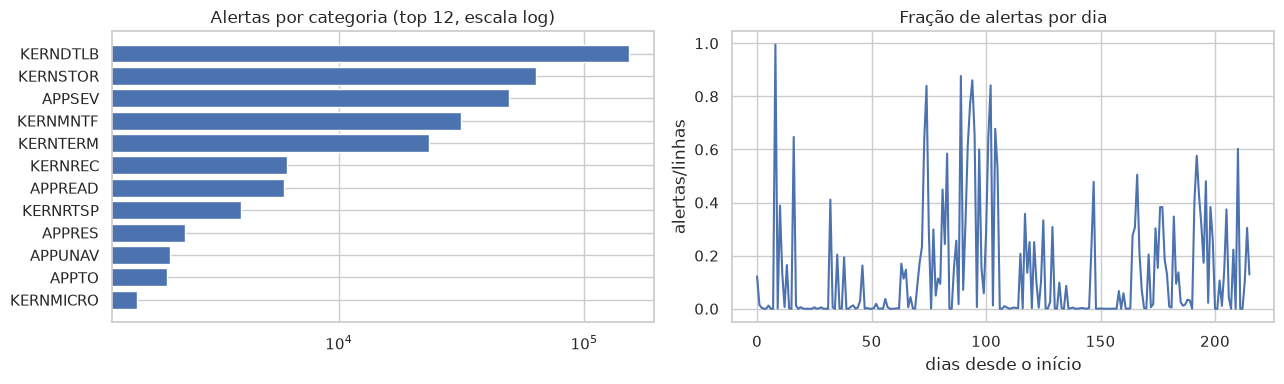

In [12]:
diario = con.sql("SELECT (epoch/86400)::int dia, count(*) n, sum((rotulo<>'-')::int) alertas FROM bgl GROUP BY 1 ORDER BY 1").df()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
top = d[d.rotulo != "-"].head(12)
ax[0].barh(top.rotulo[::-1], top.n[::-1]); ax[0].set_xscale("log"); ax[0].set(title="Alertas por categoria (top 12, escala log)")
ax[1].plot(diario.dia - diario.dia.min(), diario.alertas / diario.n); ax[1].set(title="Fração de alertas por dia", xlabel="dias desde o início", ylabel="alertas/linhas")
plt.tight_layout(); plt.show()

### 2.3 Templates e risco de vazamento do rótulo

Template aproximado = mensagem com números/hex trocados por `<N>`. (Aproximação simples; um parser como Drain daria templates mais fiéis.)

In [13]:
con.execute("""
CREATE OR REPLACE TABLE bgl_t AS
SELECT n, rotulo, nivel, no,
       regexp_replace(regexp_replace(msg, '0x[0-9a-fA-F]+', '<H>', 'g'), '[0-9]+', '<N>', 'g') AS tpl
FROM bgl
""")
t = con.sql("""
SELECT tpl, count(*) n, sum((rotulo<>'-')::int) alertas FROM bgl_t GROUP BY 1
""").df()
t["pct_alerta"] = t.alertas / t.n
print("templates distintos:", len(t))
puro_alerta = t[t.pct_alerta == 1]; puro_normal = t[t.pct_alerta == 0]; misto = t[(t.pct_alerta > 0) & (t.pct_alerta < 1)]
print(f"templates só-alerta: {len(puro_alerta):,} | só-normal: {len(puro_normal):,} | mistos: {len(misto):,}")
al = t.alertas.sum()
print(f"alertas cobertos por templates 100% alerta: {puro_alerta.alertas.sum()/al:.1%}")
print(f"linhas em templates mistos (onde o texto sozinho não decide): {misto.n.sum():,} ({misto.n.sum()/t.n.sum():.2%})")
cut_n = int(.7 * 4747963)
lk = con.sql(f"""
WITH vistos AS (SELECT DISTINCT tpl FROM bgl_t WHERE n <= {cut_n} AND rotulo <> '-')
SELECT sum((rotulo<>'-')::int) alertas, sum((rotulo<>'-' AND v.tpl IS NOT NULL)::int) pegos,
       sum((rotulo='-' AND v.tpl IS NOT NULL)::int) falsos_alarmes
FROM bgl_t b LEFT JOIN vistos v USING (tpl) WHERE b.n > {cut_n}
""").fetchone()
print(f"lookup cronológico (templates vistos como alerta nos primeiros 70% das linhas, aplicados aos 30% finais): "
      f"recall {lk[1]/lk[0]:.2%} ({lk[1]:,} de {lk[0]:,} alertas), falsos alarmes {lk[2]:,}")
lv = con.sql("SELECT sum((nivel='FATAL' AND rotulo<>'-')::int) tp, sum((nivel='FATAL')::int) pred, sum((rotulo<>'-')::int) pos FROM bgl").fetchone()
print(f"regra 'nível = FATAL': recall {lv[0]/lv[2]:.2%}, precisão {lv[0]/lv[1]:.2%}")
print(misto.sort_values("n", ascending=False).head(5)[["tpl", "n", "pct_alerta"]].assign(tpl=lambda d: d.tpl.str.slice(0, 80)).round(3).to_string(index=False))

templates distintos: 25102
templates só-alerta: 96 | só-normal: 25,002 | mistos: 4
alertas cobertos por templates 100% alerta: 81.3%
linhas em templates mistos (onde o texto sozinho não decide): 68,666 (1.45%)
lookup cronológico (templates vistos como alerta nos primeiros 70% das linhas, aplicados aos 30% finais): recall 55.86% (48,060 de 86,033 alertas), falsos alarmes 1
regra 'nível = FATAL': recall 99.98%, precisão 40.76%
                                     tpl     n  pct_alerta
                  data storage interrupt 63493       1.000
                       program interrupt  3667       0.001
                   Microloader Assertion  1504       0.999
ciodb exited normally with exit code <N>     2       0.500


### 2.4 Baseline por janela

Janelas de 100 linhas consecutivas; features = contagem dos 300 templates mais frequentes no período de treino; alvo = a janela contém ao menos um alerta; divisão **cronológica** 70/30. Como o texto da própria mensagem de alerta entra nas features, o resultado deve ser lido junto com o vazamento medido em 2.3.

In [14]:
W = 100; K = 300
N = 4747963; cut_n = int(.7 * N)
# templates escolhidos só pelas linhas do período de treino (sem olhar o futuro nem o rótulo)
top = con.sql(f"SELECT tpl FROM bgl_t WHERE n <= {cut_n} GROUP BY 1 ORDER BY count(*) DESC LIMIT {K}").df().tpl.tolist()
topdf = pd.DataFrame({"tpl": top, "k": range(len(top))})
con.register("topdf", topdf)
cnt = con.sql(f"""
SELECT ((n-1)//{W}) AS w, k, count(*) c FROM bgl_t JOIN topdf USING (tpl) GROUP BY 1, 2
""").df()
lab_w = con.sql(f"SELECT ((n-1)//{W}) AS w, max((rotulo<>'-')::int) y FROM bgl_t GROUP BY 1 ORDER BY 1").df().set_index("w")
Xw = cnt.pivot(index="w", columns="k", values="c").reindex(lab_w.index).fillna(0).reindex(columns=range(K), fill_value=0)
yw = lab_w.y.to_numpy(); Xw = Xw.to_numpy()
print("janelas:", len(yw), "| janelas com alerta:", f"{yw.mean():.1%}")
cut = int(.7 * len(yw))  # ponytail: corte por janela, alinhado ao corte por linha (70%) a menos de 1 janela
print("alertas no treino:", f"{yw[:cut].mean():.1%}", "| no teste:", f"{yw[cut:].mean():.1%}")
rb = baseline(Xw[:cut], Xw[cut:], yw[:cut], yw[cut:], "BGL janelas (cronológica)")
print(pd.DataFrame(rb).T.round(4).to_string())

janelas: 47480 | janelas com alerta: 10.1%
alertas no treino: 10.1% | no teste: 10.1%


                                        precisao  recall      f1  pr_auc
BGL janelas (cronológica) LogReg          0.8438  0.5464  0.6633  0.6379
                          RandomForest    0.9362  0.5834  0.7188  0.6611


---
## 3. Veredito de viabilidade para IA

Números abaixo vêm das saídas deste notebook (uma execução; baseline sem ajuste de hiperparâmetros, limiar 0,5).

### HDFS_v1: viável como benchmark, mas o número "fácil" engana
- **Escala e rótulo:** 575.061 traces, 2,93% de anomalias (33,2:1). Os rótulos de `anomaly_label.csv` e da matriz de eventos coincidem em 100% dos traces. Cabe na RAM (matriz de eventos: 165 MB); os 1,5 GB do log bruto só passam pelo DuckDB.
- **Redundância extrema:** só 589 vetores de contagem distintos (0,10%) e um único vetor cobre 52,2% dos traces. Na divisão aleatória (a), 100% dos vetores do teste já estão no treino, e o F1 de 0,98 a 0,999 não mede generalização.
- **Padrões novos (b):** com nenhum vetor do teste visto no treino, o F1 é 0,95 (regressão logística) e 0,97 (random forest). Esse teste tem só 2,3 a 2,7 mil traces, todos de vetores raros, com cerca de metade de anomalias; não reproduz a mistura real de classes.
- **Risco de circularidade (hipótese, não testada):** o README diz que o rótulo vem de regras manuais, e 12 dos 29 eventos só aparecem em traces anômalos (por exemplo E7, `writeBlock ... received exception`, em 19,6% das anomalias). Parte do desempenho pode refletir as regras que geraram o rótulo, não um padrão aprendido.
- **Coluna `Type`:** preenchida só nas anomalias, com 26 valores. O README não explica o significado; não foi usada.

### BGL: rótulo por linha, dificuldade real com divisão cronológica
- **Escala e rótulo:** 4.747.963 linhas, 348.460 alertas (7,34%), 41 categorias, de 2005-06-03 a 2006-01-04. Os totais batem com a documentação.
- **Atalhos triviais:** todos os alertas estão em linhas de nível FATAL (a regra `nível = FATAL` tem recall de 99,98%, mas precisão de 40,76%); no próprio conjunto, o template da mensagem quase determina o rótulo.
- **Mas o texto não generaliza no tempo:** templates vistos como alerta nos primeiros 70% das linhas pegam só 55,9% dos alertas dos 30% finais (48.060 de 86.033), com 1 falso alarme. Ou seja, 44% dos alertas futuros vêm de templates novos.
- **Baseline por janela de 100 linhas (divisão cronológica):** random forest com F1 0,72, precisão 0,94, recall 0,58 e PR-AUC 0,67; regressão logística com F1 0,66. Longe de saturado, o que torna a base mais informativa que o HDFS.
- **Qualidade:** 0,73% das linhas (34.786) têm formato irregular e o parse por regex errou o nível; os templates são aproximados (dígitos trocados por `<N>`). Um parser como o Drain daria templates mais fiéis.

### Conclusão
Para a pergunta "vale construir modelos de IA sobre isso?": **BGL com divisão cronológica** é o melhor ponto de partida dos dois, porque tem deriva temporal e não satura. **HDFS** serve para comparar métodos, desde que se avalie em padrões não vistos. Em ambos, o rótulo é derivado de regras ou de categorias da própria fonte, então os resultados dizem como bem um modelo reproduz esse rótulo, não necessariamente quão bem detecta incidentes reais.